In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, accuracy_score, matthews_corrcoef

pool = pd.read_parquet("data/pool_splits.parquet")
y = pool["label"]

P = np.load("data/preds_logistic.npz")
print(P.files)

['random_comp_pred', 'random_kmer_pred', 'clustered_comp_pred', 'clustered_kmer_pred', 'random_comp_prob', 'random_kmer_prob', 'clustered_comp_prob', 'clustered_kmer_prob']


In [2]:
cols = ["query", "target", "fident", "alnlen", "qcov", "tcov", "evalue", "bits"]

def best_hits(path):
    hits = pd.read_csv(path, sep="\t", header=None, names=cols)
    hits = hits.sort_values("bits", ascending=False)
    return hits.drop_duplicates(subset="query", keep="first").set_index("query")

best_rand = best_hits("data/search/random.m8")
best_clu = best_hits("data/search/cluster.m8")

In [3]:
def build_frame(split_col, best, model):
    test_idx = pool.index[pool[split_col] == "test"]
    name = "random" if split_col == "split_random" else "clustered"

    df = pd.DataFrame({
        "y": y[test_idx].to_numpy(),
        "pred": P[f"{name}_{model}_pred"],
        "prob": P[f"{name}_{model}_prob"],
    }, index=test_idx)

    df["fident"] = best["fident"].reindex(test_idx)
    return df

In [4]:
BANDS = [0, 0.3, 0.4, 0.5, 0.7, 0.9, 1.01]

def band_scores(df):
    d = df.copy()
    d["band"] = pd.cut(d["fident"], BANDS)
    rows = []
    for band, g in d.groupby("band", observed=True):
        if len(g) < 30 or g["y"].nunique() < 2:
            continue
        rows.append({
            "band": str(band),
            "n": len(g),
            "auc": roc_auc_score(g["y"], g["prob"]),
            "acc": accuracy_score(g["y"], g["pred"]),
            "mcc": matthews_corrcoef(g["y"], g["pred"]),
        })
    nohit = d[d["fident"].isna()]
    if len(nohit) >= 30:
        rows.append({
            "band": "no hit",
            "n": len(nohit),
            "auc": roc_auc_score(nohit["y"], nohit["prob"]),
            "acc": accuracy_score(nohit["y"], nohit["pred"]),
            "mcc": matthews_corrcoef(nohit["y"], nohit["pred"]),
        })
    return pd.DataFrame(rows)

In [5]:
for split_col, best in [("split_random", best_rand), ("split_cluster", best_clu)]:
    for model in ["comp", "kmer"]:
        print(split_col, model)
        print(band_scores(build_frame(split_col, best, model)))
        print()

split_random comp
          band     n       auc       acc       mcc
0   (0.0, 0.3]  1259  0.638652  0.675139  0.184468
1   (0.3, 0.4]  2766  0.626449  0.604121  0.137408
2   (0.4, 0.5]  2034  0.632383  0.620944  0.183560
3   (0.5, 0.7]  2479  0.637197  0.603873  0.159424
4   (0.7, 0.9]  1526  0.656690  0.612058  0.231355
5  (0.9, 1.01]  1491  0.562713  0.531858  0.064361
6       no hit  2330  0.584507  0.633047  0.134063

split_random kmer
          band     n       auc       acc       mcc
0   (0.0, 0.3]  1259  0.684998  0.687847  0.244597
1   (0.3, 0.4]  2766  0.687367  0.650759  0.258618
2   (0.4, 0.5]  2034  0.702674  0.660275  0.280810
3   (0.5, 0.7]  2479  0.687376  0.642194  0.252963
4   (0.7, 0.9]  1526  0.730060  0.663172  0.331341
5  (0.9, 1.01]  1491  0.517276  0.519115  0.031843
6       no hit  2330  0.611054  0.643777  0.167130

split_cluster comp
          band     n       auc       acc       mcc
0   (0.0, 0.3]  3206  0.653081  0.646912  0.169224
1   (0.3, 0.4]  3601  0.6

In [6]:
all_bands = []
for split_col, best in [("split_random", best_rand), ("split_cluster", best_clu)]:
    for model in ["comp", "kmer"]:
        t = band_scores(build_frame(split_col, best, model))
        t["split"] = split_col
        t["model"] = model
        all_bands.append(t)

bands_df = pd.concat(all_bands, ignore_index=True)
bands_df.to_csv("data/results_bands.csv", index=False)

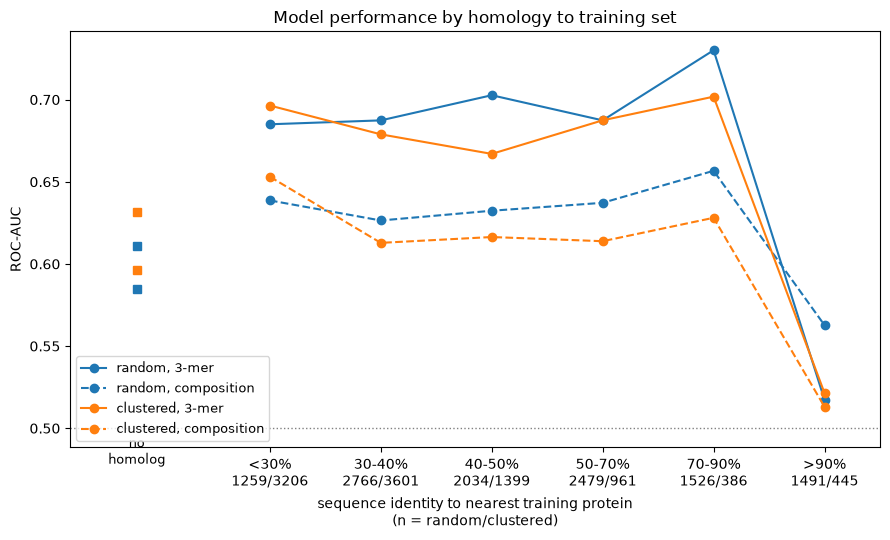

In [10]:
import matplotlib.pyplot as plt

BAND_ORDER = ["(0.0, 0.3]", "(0.3, 0.4]", "(0.4, 0.5]",
              "(0.5, 0.7]", "(0.7, 0.9]", "(0.9, 1.01]"]
LABELS = [
    "<30%\n1259/3206",
    "30-40%\n2766/3601",
    "40-50%\n2034/1399",
    "50-70%\n2479/961",
    "70-90%\n1526/386",
    ">90%\n1491/445",
]

styles = {
    ("split_random", "kmer"):  ("tab:blue",   "-",  "random, 3-mer"),
    ("split_random", "comp"):  ("tab:blue",   "--", "random, composition"),
    ("split_cluster", "kmer"): ("tab:orange", "-",  "clustered, 3-mer"),
    ("split_cluster", "comp"): ("tab:orange", "--", "clustered, composition"),
}

fig, ax = plt.subplots(figsize=(9, 5.5))

for (split, model), (color, ls, label) in styles.items():
    sub = bands_df[(bands_df["split"] == split) & (bands_df["model"] == model)]
    sub = sub.set_index("band")

    ys = [sub.loc[b, "auc"] if b in sub.index else np.nan for b in BAND_ORDER]
    ax.plot(range(len(BAND_ORDER)), ys, color=color, ls=ls,
            marker="o", label=label)

    # "no hit" plotted off to the left, disconnected from the curve
    if "no hit" in sub.index:
        ax.plot([-1.2], [sub.loc["no hit", "auc"]],
                color=color, marker="s", ls="none")

ax.axhline(0.5, color="grey", lw=1, ls=":")
ax.text(-1.2, 0.495, "no\nhomolog", ha="center", va="top", fontsize=9)

ax.set_xticks(range(len(BAND_ORDER)))
ax.set_xticklabels(LABELS)
ax.set_xlim(-1.8, len(BAND_ORDER) - 0.5)
ax.set_xlabel("sequence identity to nearest training protein")
ax.set_ylabel("ROC-AUC")
ax.set_xlabel("sequence identity to nearest training protein\n(n = random/clustered)")
ax.set_title("Model performance by homology to training set")
ax.legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.savefig("figures/auc_by_identity.png", dpi=150)
plt.show()